# 04 — State Characterization and Task Relationships

Notebook 03 fitted the TDE-HMM and saved the state dictionary plus
per-subject state time courses. This notebook does two things:

1. **Characterize** the discovered states in sensor space — their
   spectral profiles and their spatial topographies.
2. **Relate** state dynamics to the experimental variables: task phase,
   cognitive load, response accuracy, and reaction time.

**Methodological discipline.** The state dictionary was frozen in
notebook 03 without any access to labels. Labels are revealed for the
first time here. Any relationship we report between state dynamics and
task variables is therefore *discovered*, not imposed.

**Sensor-space interpretation.** EEG topographies reflect scalp
potential distributions. A state with a frontocentral scalp pattern is
consistent with activity over frontal and central regions, but this does
not by itself establish a cortical network or generator without source
localization.

**Reference method.** State characterization follows Quinn et al. (2018,
*Front. Neurosci.*): evoked fractional occupancy, aligned across trials,
analyzed against baseline. State-resolved spectral characterization
follows the OHBA TDE-HMM literature (Vidaurre et al. 2016, *NeuroImage*;
osl-dynamics toolbox).

In [20]:
# Setup for notebook 04.
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from eeg_state import config, model
from eeg_state.io import load_events, reconstruct_trials

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

TRIAL_DURATION_S = 5.0

# Load the frozen model artifacts from notebook 03.
with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    artifacts = pickle.load(f)

K = artifacts["n_states"]
print(f"Loaded model: K={K}, N_PCS={artifacts['n_pcs']}, "
      f"tde lags={artifacts['tde_lags'][0]}..{artifacts['tde_lags'][-1]}")
print(f"Development subjects: {artifacts['dev_subjects']}")


def iterate_trials(subject, artifacts):
    """Yield (eeg_segment, posteriors) for each valid trial.

    Two distinct indices: `sample_cursor` tracks position in the concatenated
    posteriors array; `length_idx` tracks position in the lengths array.
    Trial skip logic mirrors extract_trials so alignment is preserved.
    """
    fs = artifacts["target_sfreq"]
    trim = abs(artifacts["tde_lags"][0])
    n_samples = int(TRIAL_DURATION_S * fs)

    raw = mne.io.read_raw_fif(
        config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif",
        preload=True, verbose="ERROR",
    )
    data = raw.get_data() * 1e6
    trials_df = reconstruct_trials(load_events(subject))
    npz = np.load(config.DATA_DERIV / subject / f"{subject}_states.npz")
    posteriors = npz["posteriors"]
    lengths = npz["lengths"]

    sample_cursor = 0
    length_idx = 0
    for _, t in trials_df.iterrows():
        start = int(t["encoding_onset_s"] * fs)
        end = start + n_samples
        if end > data.shape[1]:
            continue
        L = int(lengths[length_idx])
        eeg = data[:, start + trim : start + trim + L]
        post = posteriors[sample_cursor : sample_cursor + L]
        sample_cursor += L
        length_idx += 1
        yield eeg, post


print("Helpers ready.")

Loaded model: K=2, N_PCS=20, tde lags=-25..25
Development subjects: ['sub-04', 'sub-05', 'sub-10', 'sub-11', 'sub-17', 'sub-24', 'sub-34', 'sub-45']
Helpers ready.


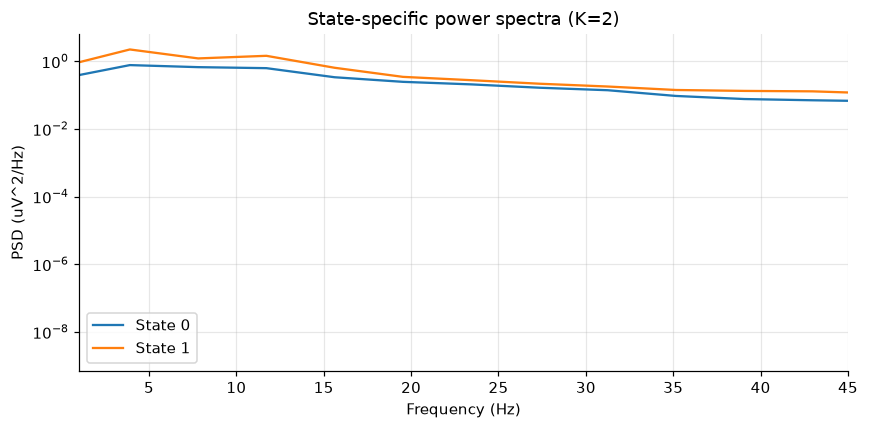

        state 0   state 1
delta  0.770185  2.232803
theta   0.66979  1.213708
alpha  0.625311  1.448932
beta   0.218957  0.331797
gamma  0.080329   0.13446


In [21]:
# Compute per-state PSD using windowed FFT weighted by state posteriors.
# Window length 64 samples (256 ms) balances spectral resolution against
# state dwell time. Soft (posterior) weighting lets windows with mixed
# states contribute proportionally.

def compute_state_spectra(subjects, artifacts, win_len=64, hop=32):
    fs = artifacts["target_sfreq"]
    K = artifacts["n_states"]
    psd_sum, weight_sum = None, None
    f = None

    for sub in subjects:
        for eeg, post in iterate_trials(sub, artifacts):
            L = eeg.shape[1]
            for w in range(0, L - win_len + 1, hop):
                seg = eeg[:, w : w + win_len]
                wp = post[w : w + win_len].mean(axis=0)
                seg = seg - seg.mean(axis=1, keepdims=True)
                taper = np.hanning(win_len)
                fft = np.fft.rfft(seg * taper, axis=1)
                pxx = (np.abs(fft) ** 2) * 2 / (fs * np.sum(taper ** 2))

                if psd_sum is None:
                    f = np.fft.rfftfreq(win_len, d=1.0 / fs)
                    psd_sum = np.zeros((K, pxx.shape[0], len(f)))
                    weight_sum = np.zeros(K)
                for k in range(K):
                    psd_sum[k] += wp[k] * pxx
                    weight_sum[k] += wp[k]

    return f, psd_sum / np.maximum(weight_sum[:, None, None], 1e-10)


f, psd = compute_state_spectra(config.DEV_SUBJECTS, artifacts)

fig, ax = plt.subplots(figsize=(8, 4))
for k in range(K):
    p = psd[k].mean(axis=0)  # channel-averaged
    ax.semilogy(f, p, label=f"State {k}", linewidth=1.5)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (uV^2/Hz)")
ax.set_xlim(1, 45)
ax.set_title(f"State-specific power spectra (K={K})")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Print band-power ratios for the key bands, useful for the markdown.
bands = {
    "delta": (0.1, 4.0),      # bin 3.906
    "theta": (4.0, 8.0),      # bin 7.812
    "alpha": (8.0, 12.0),     # bin 11.719
    "beta":  (12.0, 32.0),    # bins 15.625, 19.531, 23.438, 27.344, 31.25
    "gamma": (32.0, 45.0),    # bins 35.156, 39.062, 42.969
}
df = pd.DataFrame(index=list(bands.keys()), columns=[f"state {k}" for k in range(K)])
for name, (lo, hi) in bands.items():
    mask = (f >= lo - 1e-6) & (f <= hi + 1e-6)
    for k in range(K):
        df.loc[name, f"state {k}"] = psd[k][:, mask].mean()
print(df.round(4))

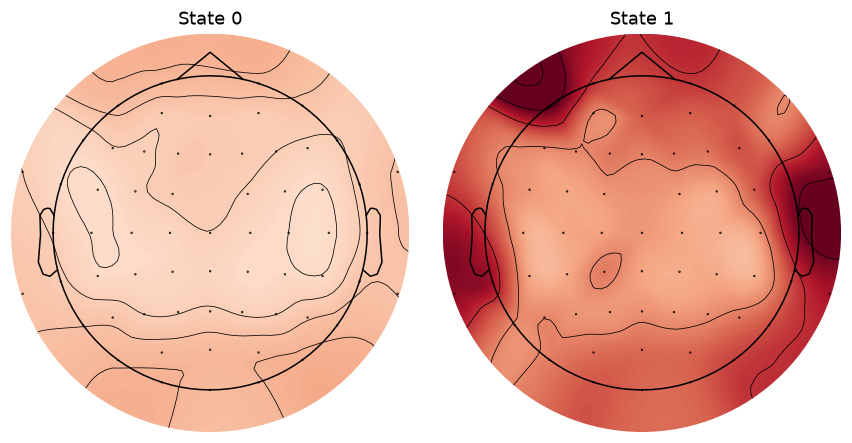

State 0 top-5 channels: [('PO8', 5.836), ('O1', 5.73), ('O2', 5.556), ('PO7', 5.469), ('PO4', 5.444)]
State 1 top-5 channels: [('AF7', 16.522), ('FT10', 15.509), ('T8', 15.325), ('FT8', 14.853), ('TP9', 14.747)]


In [32]:
# Per-state scalp power map, averaged across subjects.
# For each state, select the samples assigned to that state (hard Viterbi
# assignment) and compute the RMS amplitude per channel.

def compute_state_topography(subjects, artifacts):
    K = artifacts["n_states"]
    topo_sum = np.zeros((K, 63))
    n_subj = 0

    for sub in subjects:
        npz = np.load(config.DATA_DERIV / sub / f"{sub}_states.npz")
        viterbi = npz["viterbi"]
        fs = artifacts["target_sfreq"]
        trim = abs(artifacts["tde_lags"][0])
        n_samples = int(TRIAL_DURATION_S * fs)

        raw = mne.io.read_raw_fif(
            config.DATA_DERIV / sub / f"{sub}_preprocessed_raw.fif",
            preload=True, verbose="ERROR")
        data = raw.get_data() * 1e6
        trials_df = reconstruct_trials(load_events(sub))
        lengths = npz["lengths"]

        sub_sq = np.zeros((K, 63))
        sub_n = np.zeros(K)
        sample_cursor = 0
        length_idx = 0
        for _, t in trials_df.iterrows():
            start = int(t["encoding_onset_s"] * fs)
            if start + n_samples > data.shape[1]:
                continue
            L = int(lengths[length_idx])
            eeg = data[:, start + trim : start + trim + L]
            seg_v = viterbi[sample_cursor : sample_cursor + L]
            sample_cursor += L
            length_idx += 1
            for k in range(K):
                m = seg_v == k
                if m.any():
                    sub_sq[k] += np.sum(eeg[:, m] ** 2, axis=1)
                    sub_n[k] += m.sum()

        for k in range(K):
            if sub_n[k] > 0:
                topo_sum[k] += np.sqrt(sub_sq[k] / sub_n[k])
        n_subj += 1

    return topo_sum / n_subj


topo = compute_state_topography(config.DEV_SUBJECTS, artifacts)

# Reuse the info from a preprocessed file for the montage.
raw0 = mne.io.read_raw_fif(
    config.DATA_DERIV / config.DEV_SUBJECTS[0]
    / f"{config.DEV_SUBJECTS[0]}_preprocessed_raw.fif",
    preload=False, verbose="ERROR")

fig, axes = plt.subplots(1, K, figsize=(4 * K, 4))
if K == 1:
    axes = [axes]
vmax = np.abs(topo).max()
for k, ax in enumerate(axes):
    im, _ = mne.viz.plot_topomap(
        topo[k], raw0.info, axes=ax, show=False,
        cmap="RdBu_r", vlim=(-vmax, vmax), contours=4,
    )
    ax.set_title(f"State {k}")
plt.tight_layout()
plt.show()

# Quantify: which channels are strongest in each state?
ch_names = raw0.ch_names
for k in range(K):
    idx = np.argsort(np.abs(topo[k]))[::-1][:5]
    print(f"State {k} top-5 channels: "
          f"{[(ch_names[i], round(float(topo[k][i]), 3)) for i in idx]}")

In [36]:
# Spatial correlation between state topographies.
r = np.corrcoef(topo[0], topo[1])[0, 1]
print(f"Spatial correlation between state 0 and state 1 topographies: {r:.3f}")
print(f"Amplitude ratio (max channel): "
      f"{np.abs(topo[1]).max() / np.abs(topo[0]).max():.2f}")

Spatial correlation between state 0 and state 1 topographies: 0.535
Amplitude ratio (max channel): 2.83


In [37]:
print("State means in PCA space (20 PCs):")
print(artifacts["hmm"].means_.round(3))
print("\nComponent-wise difference (state 1 - state 0):")
print((artifacts["hmm"].means_[1] - artifacts["hmm"].means_[0]).round(3))
print("\nCovariance traces:")
for k in range(2):
    print(f"  state {k}: trace = {np.trace(artifacts['hmm'].covars_[k]):.3f}")

State means in PCA space (20 PCs):
[[ 0.001 -0.004  0.005 -0.001  0.002  0.003  0.    -0.    -0.002 -0.002
   0.011 -0.     0.003  0.01  -0.006  0.003 -0.005 -0.001  0.001 -0.001]
 [-0.008  0.06  -0.065  0.014 -0.024 -0.04  -0.002  0.     0.034  0.033
  -0.15   0.002 -0.042 -0.144  0.083 -0.042  0.069  0.01  -0.009  0.018]]

Component-wise difference (state 1 - state 0):
[-0.009  0.064 -0.069  0.015 -0.026 -0.043 -0.003  0.     0.036  0.035
 -0.161  0.002 -0.045 -0.154  0.089 -0.045  0.074  0.01  -0.01   0.019]

Covariance traces:
  state 0: trace = 15.681
  state 1: trace = 79.368


In [38]:
# Is state 1 really "more autocorrelated but not more oscillatory"?
print("State 1 cov trace / state 0 cov trace:",
      np.trace(artifacts["hmm"].covars_[1]) / np.trace(artifacts["hmm"].covars_[0]))
print("State 1 mean norm / state 0 mean norm:",
      np.linalg.norm(artifacts["hmm"].means_[1]) / np.linalg.norm(artifacts["hmm"].means_[0]))

State 1 cov trace / state 0 cov trace: 5.061301842095099
State 1 mean norm / state 0 mean norm: 13.764543014747751


In [39]:
from scipy import stats

from eeg_state.io import (
    ENCODING_DURATION, RETENTION_DURATION,
    RETRIEVAL_ONSET_OFFSET, RETRIEVAL_DURATION,
)

TRIAL_DURATION_S = 5.0
TDE_TRIM = abs(artifacts["tde_lags"][0])   # 25 samples
FS = artifacts["target_sfreq"]              # 250 Hz

RARE_STATE = int(np.argmax(np.linalg.norm(artifacts["hmm"].means_, axis=1)))
DOMINANT_STATE = 1 - RARE_STATE
print(f"Rare state index = {RARE_STATE} (occupancy ~6-7%)")
print(f"Dominant state index = {DOMINANT_STATE} (occupancy ~93%)")

Rare state index = 1 (occupancy ~6-7%)
Dominant state index = 0 (occupancy ~93%)


In [40]:
def load_trial_posteriors(subject, artifacts):
    npz = np.load(config.DATA_DERIV / subject / f"{subject}_states.npz")
    post = npz["posteriors"]
    lengths = npz["lengths"]

    raw = mne.io.read_raw_fif(
        config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif",
        preload=False, verbose="ERROR",
    )
    n_samples_raw = raw.n_times
    trials_df = reconstruct_trials(load_events(subject))

    trim = abs(artifacts["tde_lags"][0])
    n_trial_samples = int(TRIAL_DURATION_S * artifacts["target_sfreq"])
    sfreq = artifacts["target_sfreq"]

    records = []
    sample_cursor = 0
    length_idx = 0
    for _, row in trials_df.iterrows():
        start = int(row["encoding_onset_s"] * sfreq)
        end = start + n_trial_samples
        if end > n_samples_raw:
            continue
        L = int(lengths[length_idx])
        post_trial = post[sample_cursor : sample_cursor + L]
        sample_cursor += L
        length_idx += 1

        t_rel = (np.arange(L) + trim) / sfreq
        records.append({
            "subject": subject,
            "trial_idx": int(row["trial_idx"]),
            "load": int(row["load"]),
            "probe_present": bool(row["probe_present"]),
            "correct": row["correct"],
            "rt_s": row["rt_s"],
            "posteriors": post_trial,
            "t_rel": t_rel,
        })

    assert length_idx == len(lengths), (
        f"{subject}: length mismatch ({length_idx} vs {len(lengths)})"
    )
    assert sample_cursor == post.shape[0], (
        f"{subject}: sample mismatch ({sample_cursor} vs {post.shape[0]})"
    )
    return records

print("Loading per-trial posteriors ...")
all_trials = []
for sub in config.DEV_SUBJECTS:
    recs = load_trial_posteriors(sub, artifacts)
    all_trials.extend(recs)
    print(f"  {sub}: {len(recs)} trials")

print(f"\nTotal: {len(all_trials)} trials across {len(config.DEV_SUBJECTS)} subjects")

Loading per-trial posteriors ...
  sub-04: 197 trials
  sub-05: 200 trials
  sub-10: 200 trials
  sub-11: 200 trials
  sub-17: 200 trials
  sub-24: 200 trials
  sub-34: 200 trials
  sub-45: 200 trials

Total: 1597 trials across 8 subjects


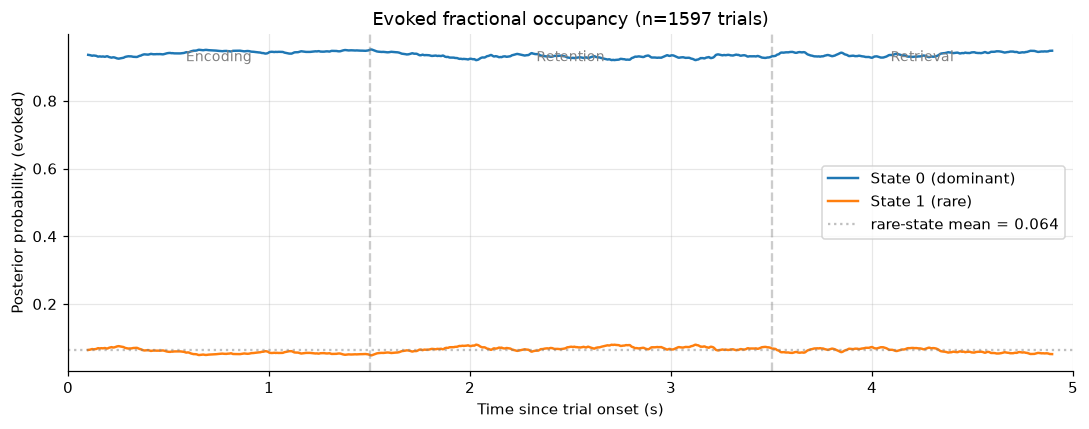

In [41]:
L_max = max(len(r["posteriors"]) for r in all_trials)
t_common = (np.arange(L_max) + TDE_TRIM) / FS   # 0.1 .. 4.9 s

post_sum = np.zeros((L_max, artifacts["n_states"]))
count = np.zeros(L_max)
for r in all_trials:
    L = len(r["posteriors"])
    post_sum[:L] += r["posteriors"]
    count[:L] += 1
evoked = post_sum / np.maximum(count[:, None], 1)

fig, ax = plt.subplots(figsize=(10, 4))
for k in range(artifacts["n_states"]):
    label = f"State {k}" + (" (rare)" if k == RARE_STATE else " (dominant)")
    ax.plot(t_common, evoked[:, k], label=label, linewidth=1.6)

rare_mean = evoked[:, RARE_STATE].mean()
ax.axhline(rare_mean, color="gray", linestyle=":", alpha=0.5,
           label=f"rare-state mean = {rare_mean:.3f}")

for x in (ENCODING_DURATION, RETRIEVAL_ONSET_OFFSET):
    ax.axvline(x, color="gray", linestyle="--", alpha=0.4)
ymax = ax.get_ylim()[1]
ax.text(0.75, ymax * 0.92, "Encoding", ha="center", fontsize=9, color="gray")
ax.text(2.5, ymax * 0.92, "Retention", ha="center", fontsize=9, color="gray")
ax.text(4.25, ymax * 0.92, "Retrieval", ha="center", fontsize=9, color="gray")

ax.set_xlabel("Time since trial onset (s)")
ax.set_ylabel("Posterior probability (evoked)")
ax.set_title(f"Evoked fractional occupancy (n={len(all_trials)} trials)")
ax.set_xlim(0, TRIAL_DURATION_S)
ax.legend(loc="center right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

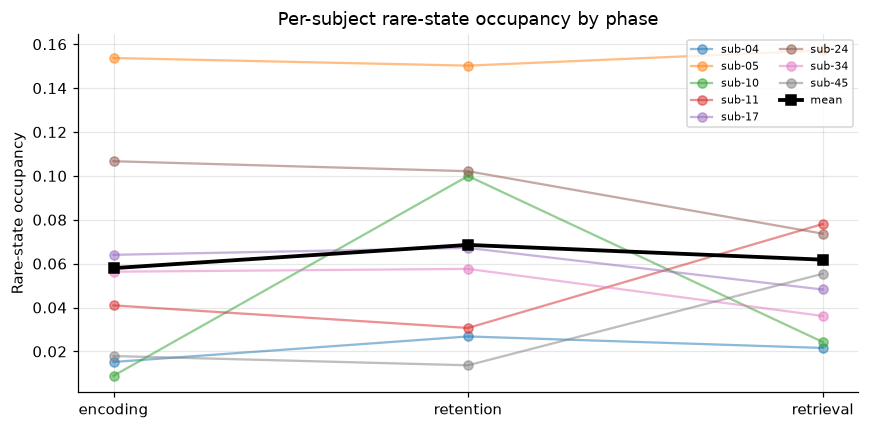

Friedman across phases: chi2 = 0.250,  p = 0.8825

phase    encoding  retention  retrieval
subject                                
sub-04      0.015      0.027      0.022
sub-05      0.154      0.150      0.157
sub-10      0.009      0.100      0.024
sub-11      0.041      0.031      0.078
sub-17      0.064      0.067      0.048
sub-24      0.107      0.102      0.074
sub-34      0.056      0.058      0.036
sub-45      0.018      0.014      0.055


In [42]:
def phase_means(t_rel, posteriors):
    """Mean posterior per state in encoding, retention, retrieval."""
    masks = {
        "encoding":  (t_rel >= 0) & (t_rel < ENCODING_DURATION),
        "retention": (t_rel >= ENCODING_DURATION) & (t_rel < RETRIEVAL_ONSET_OFFSET),
        "retrieval": (t_rel >= RETRIEVAL_ONSET_OFFSET) & (t_rel < TRIAL_DURATION_S),
    }
    return {name: posteriors[m].mean(axis=0) for name, m in masks.items()}


phase_rows = []
for r in all_trials:
    for phase, p in phase_means(r["t_rel"], r["posteriors"]).items():
        phase_rows.append({
            "subject": r["subject"],
            "trial_idx": r["trial_idx"],
            "phase": phase,
            "occ_rare": p[RARE_STATE],
        })
phase_df = pd.DataFrame(phase_rows)

subj_phase = phase_df.groupby(["subject", "phase"])["occ_rare"].mean().unstack()
phases = ["encoding", "retention", "retrieval"]

fig, ax = plt.subplots(figsize=(8, 4))
for sub in subj_phase.index:
    ax.plot(phases, subj_phase.loc[sub, phases].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(phases, subj_phase[phases].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_ylabel("Rare-state occupancy")
ax.set_title("Per-subject rare-state occupancy by phase")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[subj_phase[ph].values for ph in phases])
print(f"Friedman across phases: chi2 = {stat:.3f},  p = {p:.4f}")
print()
print(subj_phase.round(3))

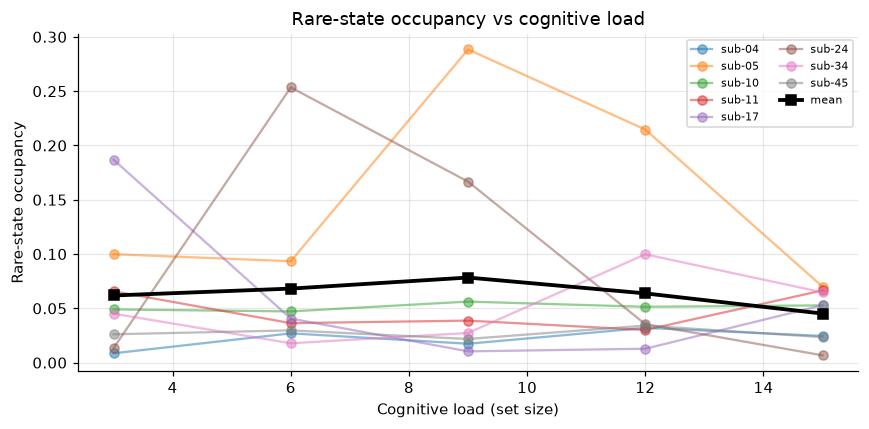

Friedman across loads: chi2 = 1.100,  p = 0.8943

load        3      6      9      12     15
subject                                   
sub-04   0.009  0.027  0.017  0.032  0.025
sub-05   0.100  0.093  0.288  0.215  0.070
sub-10   0.049  0.047  0.056  0.051  0.053
sub-11   0.066  0.036  0.039  0.030  0.067
sub-17   0.187  0.041  0.010  0.013  0.053
sub-24   0.013  0.254  0.167  0.035  0.007
sub-34   0.045  0.018  0.027  0.100  0.065
sub-45   0.026  0.030  0.022  0.034  0.024


In [43]:
load_rows = []
for r in all_trials:
    load_rows.append({
        "subject": r["subject"],
        "load": r["load"],
        "occ_rare": r["posteriors"][:, RARE_STATE].mean(),
    })
load_df = pd.DataFrame(load_rows)

subj_load = load_df.groupby(["subject", "load"])["occ_rare"].mean().unstack()
# Drop any load column with NaN (subject missing that set size)
subj_load_clean = subj_load.dropna(axis=1)
loads = sorted(subj_load_clean.columns)

fig, ax = plt.subplots(figsize=(8, 4))
for sub in subj_load_clean.index:
    ax.plot(loads, subj_load_clean.loc[sub, loads].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(loads, subj_load_clean[loads].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_xlabel("Cognitive load (set size)")
ax.set_ylabel("Rare-state occupancy")
ax.set_title("Rare-state occupancy vs cognitive load")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[subj_load_clean[l].values for l in loads])
print(f"Friedman across loads: chi2 = {stat:.3f},  p = {p:.4f}")
print()
print(subj_load_clean.round(3))

        occ_rare  accuracy  rt_median
sub-04     0.022     0.807      1.058
sub-05     0.153     0.770      0.758
sub-10     0.051     0.815      0.745
sub-11     0.047     0.835      0.917
sub-17     0.061     0.760      0.792
sub-24     0.095     0.750      0.972
sub-34     0.051     0.870      1.058
sub-45     0.027     0.830      1.071


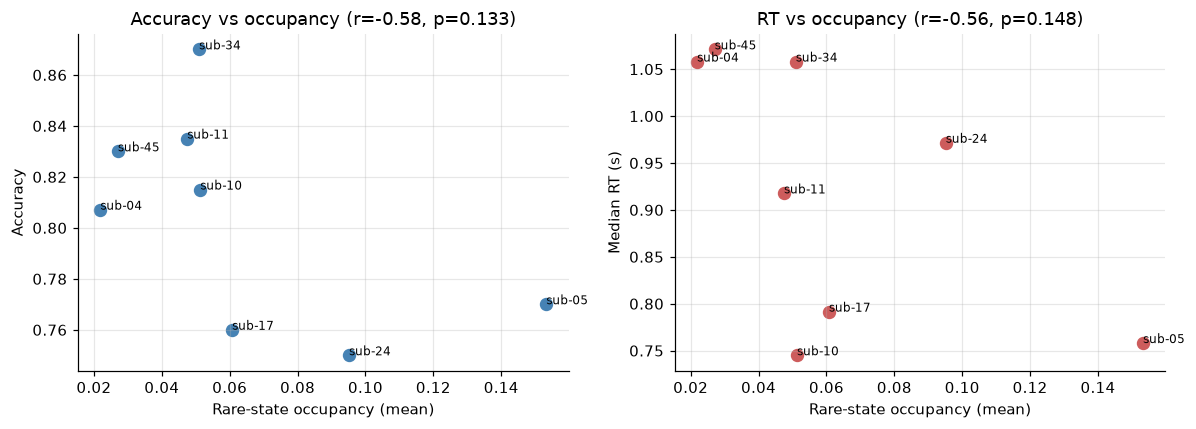

In [44]:
# Per-subject rare-state occupancy
occ_by_subj = load_df.groupby("subject")["occ_rare"].mean()

# Per-subject accuracy and median RT (from event reconstruction)
acc_by_subj, rt_by_subj = {}, {}
for sub in config.DEV_SUBJECTS:
    trials = reconstruct_trials(load_events(sub))
    acc_by_subj[sub] = trials["correct"].mean()      # NaN-skipped
    rt_by_subj[sub]  = trials["rt_s"].median()

behavioral = pd.DataFrame({
    "occ_rare":  occ_by_subj,
    "accuracy":  pd.Series(acc_by_subj),
    "rt_median": pd.Series(rt_by_subj),
})
print(behavioral.round(3))

r_acc, p_acc = stats.pearsonr(behavioral["occ_rare"], behavioral["accuracy"])
r_rt,  p_rt  = stats.pearsonr(behavioral["occ_rare"], behavioral["rt_median"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(behavioral["occ_rare"], behavioral["accuracy"],
                color="steelblue", s=60)
for sub, row in behavioral.iterrows():
    axes[0].annotate(sub, (row["occ_rare"], row["accuracy"]), fontsize=8)
axes[0].set_xlabel("Rare-state occupancy (mean)")
axes[0].set_ylabel("Accuracy")
axes[0].set_title(f"Accuracy vs occupancy (r={r_acc:.2f}, p={p_acc:.3f})")
axes[0].grid(alpha=0.3)

axes[1].scatter(behavioral["occ_rare"], behavioral["rt_median"],
                color="indianred", s=60)
for sub, row in behavioral.iterrows():
    axes[1].annotate(sub, (row["occ_rare"], row["rt_median"]), fontsize=8)
axes[1].set_xlabel("Rare-state occupancy (mean)")
axes[1].set_ylabel("Median RT (s)")
axes[1].set_title(f"RT vs occupancy (r={r_rt:.2f}, p={p_rt:.3f})")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()